# Settlement Ledgers on the WSCC 9-Bus Network

> **Work in progress** — an illustrative teaching notebook under active development, not an authoritative reference.

This notebook defines the three
settlement ledgers: the congestion-revenue ledger, the transfer-revenue ledger,
and the position ledger. It derives the congestion revenue by region, the net
congestion position $N_a^c$, measured against each region's own ex-ante
aggregation point. It closes with an autarky Pareto check and a sandbox. The
full program and its duals are derived in 101; Section 1 restates the objects
the ledgers price, so this notebook stands on its own math.

Everything runs on the shared teaching libraries (`wscc9_model`,
`footprints`, `revenue_allocation`, `wscc9_figures`) built on the `seams_engine`
PTDF DC-OPF and the `nodal_plot` figures.


## 0. Setup

In [1]:
#@title ▶ Run me first — Colab setup (installs packages, fetches the helper modules)
# On Google Colab this installs the few non-default packages and downloads the
# helper modules next to the notebook. Running locally it does nothing
# (the modules are already on disk), so the same notebook works in both places.
import sys, subprocess

def _sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)

if "google.colab" in sys.modules:
    _sh("pip install -q pypsa pandapower pycirclize")
    _base = "https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/main"
    for _f in ("ieee9_network.py", "seams_engine.py", "nodal_plot.py",
               "wscc9_model.py", "footprints.py", "revenue_allocation.py",
               "wscc9_figures.py", "atc.py", "bilateral.py"):
        _sh(f"wget -q {_base}/{_f} -O {_f}")
    print("Colab setup complete.")
else:
    print("Local run: using the modules already in this folder.")


Local run: using the modules already in this folder.


In [2]:
import sys, os, importlib
import warnings; warnings.filterwarnings('ignore')
import logging; logging.getLogger('pypsa').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))

# Teaching libraries for the WSCC 9-bus illustrative repository.
import seams_engine, nodal_plot, wscc9_model, footprints, revenue_allocation, wscc9_figures
for _m in (seams_engine, nodal_plot, wscc9_model, footprints, revenue_allocation, wscc9_figures):
    importlib.reload(_m)
import wscc9_model as wm, footprints as fpmod, revenue_allocation as ra, wscc9_figures as figs
from wscc9_model import (
    build_network, make_engine, shift_factors, sf_table,
    BUS_COLORS, COORDS, RING_ORDER, ROTATION_DEG, CENTER_BUS,
)
from seams_engine import (
    compute_ptdf, MarketEngine, solve_engine_dispatch, solve_engine_transfers,
    physical_flows, seam_dual_gap, to_supply_demand, susceptance_widths,
    shed_segments, served_by_bus, served_demand,
)
from nodal_plot import (
    plot_network_topology, plot_nodal_circlize, plot_combined_letter,
    assign_bus_colors, BUS_PALETTE, TRANSIT_COLOR,
)
pd.set_option('display.width', 160)

# Clean tables on PDF export: give DataFrames/Series a booktabs LaTeX rendering.
# Jupyter and Colab still show the normal HTML tables; `nbconvert --to pdf` picks
# up this text/latex representation, so tables come out as real ruled tables.
figs.install_latex_repr()

print('ready')

ready

In [3]:
# The teaching fleet, loads, and the two-region partition -- the same case 101
# clears (bus 3 is the cheapest unit at $20, bus 1 the dearest at $50).
GEN_FLEET = dict(wm.DEFAULT_GEN_FLEET)   # {gen: {bus, cost $/MWh, p_nom MW}}
LOADS     = dict(wm.DEFAULT_LOADS)       # {bus: MW}

REGIONS = {'Region A': ['2', '8', '7', '6', '3'], 'Region B': ['1', '9', '4', '5']}
REGION_COLORS = {'Region A': '#993AFF', 'Region B': '#2471A3'}
REGION_LINES  = {'Region A': ['line_2', 'line_3', 'line_4', 'line_5', 'line_6'],
                 'Region B': ['line_0', 'line_1', 'line_7', 'line_8']}
ptU = shift_factors()
fp  = fpmod.make(ptU, REGIONS, REGION_COLORS, manage=REGION_LINES, tie_label='tie')

print('loads (MW):', LOADS)
pd.DataFrame(GEN_FLEET).T[['bus', 'cost', 'p_nom']]


INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


loads (MW):

{'5': 90.0, '7': 100.0, '9': 125.0}

,bus,cost,p_nom
gen_slack_0,1,50.0,250.0
gen_0,2,35.0,300.0
gen_1,3,20.0,170.0


## 1. The clearing the ledgers read

The ledgers of this notebook settle the clearings of the shared 9-bus network.
The canonical program, its Lagrangian, and the price derivations are stated in
101. This section restates the program compactly and defines the two rents the
ledgers collect, so that every quantity used below is defined here. The scope
of this notebook does not include picking an allocation rule for the collected
rents. 201 is devoted to that question.

**Nomenclature.** Sets are script capitals; an element is the matching
lower-case letter.

| Symbol | Code | Definition |
|---|---|---|
| $\mathcal N$ | `pt.buses` | the set of buses in the network; $n\in\mathcal N$ |
| $\mathcal A$ | `REGIONS` keys | the set of balancing-authority areas; $a\in\mathcal A$, and the $\mathcal N_a$ partition $\mathcal N$ |
| $\mathcal N_a$ | `REGIONS[a]` | the bus set of balancing-authority area $a$ |
| $\mathcal M$ / $\mathcal M_{\mathrm{act}}$ | `pt.lines` / `activated` | the network line set; the activated subset whose limits the clearing enforces |
| $\mathcal I\subseteq\mathcal A\times\mathcal A$ | `interfaces` (`solve_engine_transfers`) | the **declared interface set** — the ordered area pairs $(a,b)$ carrying a scheduled transfer; both orientations of a declared interface are members |
| $\mathcal R$; $c_i,\ \bar g_i,\ g_i$ | `eng.gens` / `res.dispatch` | the resources: marginal cost, capacity, and dispatch of resource $i$ at bus $\mathrm{bus}(i)$ |
| $d_n$ / $g_n$ | `eng.loads` / `res.gen_by_bus` | load at bus $n$; dispatch at bus $n$, $g_n=\sum_{i:\,\mathrm{bus}(i)=n}g_i$ |
| $SF_{n,m}$ / $F_m$ / $\bar F_m$ | `pt` | shift factor of bus $n$ on line $m$; flow $F_m=\sum_n SF_{n,m}(g_n-d_n)$; rating |
| $t_{ab}$ / $\bar T_{ab}$ | `res.transfers` / `TRANSFER_LIMIT` | scheduled transfer $a\to b$ (flow-inert); the interface's released capacity |
| $\hat\lambda_a$ / $\mu_m$ / $\mu_T^{ab}$ | `res.area_prices` / `res.line_dual` / `res.transfer_duals` | area $a$'s energy price (its balance dual); line $m$'s signed shadow price; the interface shadow price |
| $\lambda_n$ | `res.lmp` | the locational marginal price at bus $n$ |
| $w^a_n,\ \lambda_a,\ SF^a_m$ | `hub_weights` | area $a$'s ex-ante aggregation-point weights on its **own** buses ($\sum_n w^a_n=1$), its hub price, and its hub shift factor (Section 3) |
| $L_a$, $G_a$, $N_a$ | `ra.ba_settlement` | area $a$'s load payment, generation revenue, and net settlement position $L_a-G_a$ |
| $e_a$ | `ra.regional_congestion` | area $a$'s net import $\sum_{n\in a}(d_n-g_n)$ |
| $N_a^c$, $F_m^a$ | `ra.regional_congestion` | congestion by region against the area's own hub, and area $a$'s flow contribution on line $m$ (Section 3) |
| $T_E$ | `ra.transfer_settlement` | the hub-to-hub transfer settlement (Section 3) |
| $R$, $R_T$ | `settlement_by_bus` / `ra.transfer_rent` | the pooled congestion rent and transfer rent |

**The program.** The clearing minimizes production cost subject to one power
balance per balancing-authority area, the activated line limits, and the
released capacity on each declared interface:

$$\begin{aligned}
\min_{0\le g_i\le \bar g_i,\ t\ge 0}\ \ C \;&=\; \sum_{i\in\mathcal R} c_i\,g_i \\[2pt]
\text{s.t.}\quad \sum_{i\in\mathcal R:\,\mathrm{bus}(i)\in\mathcal N_a} g_i \;&=\; \sum_{n\in\mathcal N_a} d_n+\sum_{b}\big(t_{ab}-t_{ba}\big),\quad a\in\mathcal A && [\hat\lambda_a] \\
-\bar F_m \;\le\; F_m \;&\le\; \bar F_m,\quad m\in\mathcal M_{\mathrm{act}} && [\mu_m] \\
t_{ab} \;&\le\; \bar T_{ab},\quad (a,b)\in\mathcal I && [\mu_T^{ab}]
\end{aligned}\qquad\qquad(1)$$

*In words.* The clearing minimizes the dispatch cost $C=\sum_i c_i\,g_i$ over
the resources $\mathcal R$, choosing each resource's dispatch $g_i$ within its
capacity, $0\le g_i\le\bar g_i$, and non-negative scheduled transfers $t$,
subject to three constraint families: one power balance per balancing-authority
area $a\in\mathcal A$, whose generation inside the area equals the load there
plus its net scheduled transfer $\sum_b\big(t_{ab}-t_{ba}\big)$ (dual
$\hat\lambda_a$, area $a$'s energy price); the flow $F_m$ held within the
rating $\bar F_m$ on each activated line $m\in\mathcal M_{\mathrm{act}}$ (dual
$\mu_m$, that line's signed shadow price); and each scheduled transfer
$t_{ab}$ over the declared interface set $\mathcal I$ held within its released
capacity $\bar T_{ab}$ (dual $\mu_T^{ab}$, that interface's shadow price).
A clearing with no declared interface is the pooled special case, every
$\hat\lambda_a$ collapses to the one energy price $\lambda$, and
`solve_engine_dispatch` solves it directly.

**The bus price.**

$$\lambda_n \;=\; \hat\lambda_a+\sum_{m\in\mathcal M_{\mathrm{act}}}SF_{n,m}\,\mu_m,
\qquad n\in\mathcal N_a. \qquad\qquad(2)$$

*In words.* Bus $n$'s locational marginal price $\lambda_n$ is its own area's
energy price $\hat\lambda_a$ plus, over every activated line
$m\in\mathcal M_{\mathrm{act}}$, the bus's shift factor $SF_{n,m}$ onto that
line times the line's signed shadow price $\mu_m$. 101 derives this identity
from the Lagrangian; the ledgers below read it.

**The two rents.**

$$R \;=\; \sum_{m\in\mathcal M_{\mathrm{act}}}|\mu_m|\,|F_m|
   \;=\; \sum_{n\in\mathcal N}\lambda_n d_n-\sum_{n\in\mathcal N}\lambda_n g_n, \qquad\qquad(3)$$

*In words.* The congestion rent $R$, the merchandising surplus, is the absolute
shadow price $|\mu_m|$ times the absolute flow $|F_m|$, summed over the
activated lines. It equals what all load pays, $\sum_n\lambda_n d_n$, minus
what all generation is paid, $\sum_n\lambda_n g_n$, because the energy
components net to zero when total generation equals total load.

$$R_T \;=\; \sum_{(a,b)\in\mathcal I}\mu_T^{ab}\,t_{ab}. \qquad\qquad(4)$$

*In words.* The transfer rent $R_T$ is each interface's shadow price
$\mu_T^{ab}$ times the scheduled transfer $t_{ab}$ on it, summed over the
declared interface set $\mathcal I$. It is collected at the interfaces, the
transport analogue of the line rent $R$.


## 2. The three settlement ledgers

Every later notebook settles with one of three ledgers, and this section builds the first of them. Positions sum to $-(\text{production cost})$, and any pure transfer price nets out at the system total.

1. **Congestion-revenue ledger** — each region's consumers and generators at nodal
   LMPs. The congestion rent $R$ is the gap between what all load pays and what all generation is paid. It is money the system holds, and it lands in the TOTAL column. The congestion revenue is derived by region below, so the per-region piece that sums to $R$ is kept separate from the net settlement position $L_a-G_a$, which is dominated by inter-region energy trade. How the pooled rent is then allocated between the
   balancing authorities is a policy choice, not a fact of the dispatch. The scope of this notebook does not include picking an allocation rule. 201 is devoted to it.
2. **Transfer-revenue ledger** — the same layout for the transport-constrained clear:
   the transfer rent $R_T=\mu_T^{ab}\,t_{ab}$, collected at the interface, joins the TOTAL.
3. **Position ledger** — per-region net positions (consumers, generator surplus, a trader/self-schedule row), the form the seams and two-settlement notebooks use.

### The congestion-revenue ledger — two views of the system rent

This is the first of the three ledgers. It takes the unified clearing with `line_4` (6–7) capped at 40 MW, the single-constraint case this notebook uses throughout, and reads the congestion rent $R$ two equal ways. **Settlement by node** lists what every bus's load pays and every
bus's generation is paid at the nodal LMPs. The `Total − congestion rent` row is *paid by
load* minus *paid to gen*, the residual the system holds. **Marginal value of line capacity**
prices each line at $|\mu_m|\times$ flow. The `TOTAL` row sums to the same $R$, and the `binding` column flags the line that constrains.

In [4]:
# (1) Congestion-revenue ledger -- the pooled system rent R, two equal ways.  Same clearing the
# rest of this notebook uses: line_4 (6-7) capped at 40 MW (a single binding constraint, so the
# per-region split below stays clean).  settlement_by_bus and capacity_value_by_line are the
# shared helpers every later notebook settles with.
from revenue_allocation import settlement_by_bus, capacity_value_by_line
rat_c = {'line_4': 40.0}
n_c = build_network(rat_c); p_c = compute_ptdf(n_c, slack_bus='1')
r_c = solve_engine_dispatch(p_c, make_engine('UNIFIED', buses=p_c.buses), shed_price=150.0)

node_ledger = settlement_by_bus(r_c, p_c.buses, LOADS)
_lp = node_ledger.loc['SUBTOTAL', 'paid by load ($/h)']
_gp = node_ledger.loc['SUBTOTAL', 'paid to gen ($/h)']
node_ledger.loc['Total - congestion rent'] = ['', '', '', '', round(_lp - _gp, 1)]
print('Settlement by node (unified clearing, line_4 capped at 40 MW):')
display(node_ledger)
print('Marginal value of line capacity -- shadow price x flow (TOTAL = congestion rent):')
display(capacity_value_by_line(r_c, p_c, p_c.lines))

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


Settlement by node (unified clearing, line_4 capped at 40 MW):

,LMP ($/MWh),gen (MW),paid to gen ($/h),load (MW),paid by load ($/h)
bus,,,,,
1,27.74,0.0,0.0,0.0,0.0
2,35.0,176.1,6162.4,0.0,0.0
3,20.0,138.9,2778.6,0.0,0.0
4,27.74,0.0,0.0,0.0,0.0
5,25.02,0.0,0.0,90.0,2251.8
6,20.0,0.0,0.0,0.0,0.0
7,37.13,0.0,0.0,100.0,3712.6
8,35.0,0.0,0.0,0.0,0.0
9,30.25,0.0,0.0,125.0,3780.8


Marginal value of line capacity -- shadow price x flow (TOTAL = congestion rent):

,from,to,flow (MW),rating (MW),binding,|mu| ($/MWh = value of +1 MW),rent |mu| x flow ($/h)
line,,,,,,,
line_0,1,4,-0.0,250.0,False,0.0,0.0
line_1,4,5,-8.9,250.0,False,0.0,0.0
line_2,5,6,-98.9,150.0,False,0.0,0.0
line_3,3,6,138.9,300.0,False,0.0,0.0
line_4,6,7,40.0,40.0,True,20.1,804.1
line_5,7,8,-60.0,250.0,False,0.0,0.0
line_6,8,2,-176.1,250.0,False,0.0,0.0
line_7,8,9,116.1,250.0,False,0.0,0.0
line_8,9,4,-8.9,250.0,False,0.0,0.0


## 3. The congestion revenue by region

Section 1 priced every bus, eq. (2), and collected the system rent, eq. (3). That rent is split here across the balancing authorities. Each region is measured against its
**own ex-ante aggregation point** (hub): weights $w^a_n\ge0$ on region $a$'s own buses,
$\sum_n w^a_n=1$, built from the same inputs that define the region, nameplate generation where it has generation and load otherwise (`hub_weights`). The hub shift factor
and hub price are the weighted averages

$$SF^a_m=\sum_{n\in a}w^a_n\,SF_{n,m},\qquad \lambda_a=\sum_{n\in a}w^a_n\,\lambda_n, \qquad\qquad (5)$$

*In words.* Region $a$'s hub shift factor $SF^a_m$ is the weighted average of the region's own bus shift factors onto line $m$, and its hub price $\lambda_a$ is the weighted average of its own bus LMPs $\lambda_n$, both weighted by the same ex-ante aggregation-point weights $w^a_n$, which sum to one over the region's own buses.

Because the weights sum to one, substituting the bus price (2) into the hub price of (5) gives $\lambda_a=\hat\lambda_a+\sum_m SF^a_m\,\mu_m$, and every bus price is its region's energy price plus congestion **relative to the
region's own hub** (a binding transfer's price adder is constant across the region's
buses, so it sits entirely inside $\lambda_a$):

$$\lambda_n=\lambda_a+\sum_m\big(SF_{n,m}-SF^a_m\big)\,\mu_m,\qquad n\in a. \qquad\qquad (6)$$

*In words.* Bus $n$'s LMP $\lambda_n$ is its region's hub price $\lambda_a$ plus, for each line $m$, that line's shadow price $\mu_m$ times the bus's shift factor $SF_{n,m}$ measured relative to the region's own hub shift factor $SF^a_m$. Congestion is priced against the region's own aggregation point rather than against the slack bus.

**Region $a$'s net settlement position** — what its load pays minus what its generators
are paid:

$$N_a \;=\; L_a - G_a
     \;=\; \sum_{n\in a}\lambda_n d_n - \sum_{n\in a}\lambda_n g_n
     \;=\; \sum_{n\in a}\lambda_n\,(d_n-g_n). \qquad\qquad (7)$$

*In words.* Region $a$'s net settlement position $N_a$ is what its load pays, $L_a=\sum_{n\in a}\lambda_n d_n$, minus what its generation is paid, $G_a=\sum_{n\in a}\lambda_n g_n$. Equivalently, it is each bus's own net position $d_n-g_n$ valued at that bus's own LMP $\lambda_n$, summed over the region.

**Substitute the price (6)** and collect the two terms:

$$N_a \;=\; \underbrace{\lambda_a\!\sum_{n\in a}(d_n-g_n)}_{=\;\lambda_a\,e_a}
     \;+\; \underbrace{\sum_{m}\mu_m\!\sum_{n\in a}\big(SF_{n,m}-SF^a_m\big)(d_n-g_n)}_{=\;N_a^{c}}. \qquad (8)$$

*In words.* Region $a$'s net settlement position $N_a$ splits into two terms. The
first is the region's net import $e_a=\sum_{n\in a}(d_n-g_n)$ valued at its own
hub price $\lambda_a$. The second is the region's congestion by region
$N_a^{c}$, each line's shadow price $\mu_m$ times the hub-relative shift factor
$SF_{n,m}-SF^a_m$ of each bus's net position $d_n-g_n$, summed over the region's
buses and over the lines.

Rearranging, the load bill reads $L_a=G_a+\lambda_a e_a+N^c_a$. Load pays for the
generation that serves it, its own units plus its net imports at the region's own
energy price, and on top of that its own congestion.

**The congestion revenue by region — two equal forms.** Write region $a$'s own
contribution to the flow on line $m$ as $F_m^a=\sum_{n\in a}(SF_{n,m}-SF^a_m)(g_n-d_n)$, every position paired with the region's own hub. The congestion term of (8) can be read off the prices or built from the network, the same number either way:

$$N_a^{c}
  \;=\; \underbrace{\sum_{n\in a}(\lambda_n-\lambda_a)(d_n-g_n)}_{\text{(a) from the prices}}
  \;=\; \underbrace{-\sum_{m}\mu_m\,F_m^a}_{\text{(b) from the network}}. \qquad\qquad (9)$$

*In words.* Region $a$'s congestion by region $N_a^{c}$, read from the prices in
form (a), is the deviation of each bus's LMP from the region's hub price,
$\lambda_n-\lambda_a$, times that bus's net position $d_n-g_n$, summed over the
region's own buses. Read from the network in form (b), the same $N_a^{c}$ is
minus the sum over lines of each line's shadow price $\mu_m$ times region $a$'s
own flow contribution $F_m^a$ on that line. The two forms are equal because the
price deviation is the hub-relative shift-factor-weighted shadow price,
$\lambda_n-\lambda_a=\sum_m(SF_{n,m}-SF^a_m)\mu_m$.

Because every term is a difference of prices or of shift factors, the number does
not depend on where the power-flow calculation put its reference bus. The
companion table below works form (b) bus by bus. Each bus's net injection times
its hub-relative shift factor is the flow it adds to the constrained line, and
$-\mu_m$ times that flow is the congestion it causes ($+$) or relieves ($-$). The
region subtotals are $F_m^a$ and $N_a^{c}$, and a **Transfer (hub-to-hub)** row
carries the flow the scheduled interchange itself places on the line. At the
transaction level a delivery of $q$ from generator $s$ to load $k$ pays
$q(\lambda_k-\lambda_s)=q\sum_m(SF_{k,m}-SF_{s,m})\mu_m$, the same $\mu_m$ times
the gen-to-load shift factor, with every hub canceling out entirely.

**It partitions the collected surplus, together with the transfer settlement.** The
scheduled interchange settles hub-to-hub as the **transfer settlement**
$T_E=\sum_a\lambda_a e_a=t_{12}\,(\lambda_2-\lambda_1)$, and summing (8) over the regions,

$$\sum_a N_a^{c} \;+\; T_E \;=\; R \;+\; R_T. \qquad\qquad (10)$$

*In words.* Summed across every region, the congestion revenue by region $N_a^{c}$ plus the transfer settlement $T_E$ equals the system's congestion rent $R$ plus the transfer rent $R_T$.

$T_E$ carries the transfer rent $R_T=\mu_T^{12}\,t_{12}$ whenever the schedule binds, plus the line-congestion value of the transfer's own hub-to-hub flow. It is therefore generally nonzero even when the schedule is slack, and negative when that flow is net counterflow on the binding lines. A region with no interchange ($e_a=0$) has an $N_a^{c}$ that is the same number under any hub. The convention only matters for the unbalanced part.

**The net settlement position is not the congestion revenue.** $L_a-G_a$ is $N_a$, and (8) shows it also carries the energy term $\lambda_a e_a$, which for an importer dwarfs the congestion. Most of its $L_a-G_a$ is the
bill for imported energy that pays other regions' generators, so it is a net
settlement position, not congestion revenue.

In [5]:
# (1) Congestion-revenue ledger -- unpack each region's load bill into the generation it
# pays for and the congestion it bears, each region measured against its OWN ex-ante
# aggregation point (hub):   L_a = G_a + lambda_a*e_a + N_a^c.
rat_c = {'line_4': 40.0}
n_c = build_network(rat_c); p_c = compute_ptdf(n_c, slack_bus='1')
r_c = solve_engine_dispatch(p_c, make_engine('UNIFIED', buses=p_c.buses), shed_price=150.0)
lam_c = float(r_c.energy_price)

rc = ra.regional_congestion(fp, r_c, p_c, LOADS)
cong = pd.DataFrame({reg: {
    'Load payment  L_a':                                    rc[reg]['load_pay'],
    'Gen revenue WITHIN region  G_a':                       rc[reg]['gen_rev_within'],
    'Net import  e_a  (MW)':                                rc[reg]['net_import'],
    'Hub (aggregation-point) price  lambda_a':              rc[reg]['hub_price'],
    'Net import @ own hub  (lambda_a*e_a)':                 rc[reg]['energy_payment'],
    'Generation payment serving region  (G_a + lambda_a*e_a)': rc[reg]['gen_payment'],
    'Congestion revenue by region  N_a^c':                  rc[reg]['line_congestion'],
} for reg in fp.areas})
cong['TOTAL'] = cong.sum(axis=1)
sum_nc = sum(rc[reg]['line_congestion'] for reg in fp.names)
TE_c = ra.transfer_settlement(fp, r_c, LOADS)
print('identity per region:   L_a  =  (G_a + lambda_a*e_a)  +  N_a^c    (each region against its OWN hub)')
print(f'congestion by region sums to ${sum_nc:,.0f};  + transfer settlement T_E = ${TE_c:,.0f}  ->  collected R = ${sum_nc + TE_c:,.0f}')
display(cong.round(1))

# Second table -- the shift-factor build-up of the congestion-revenue-by-region (eq 9,
# network form): each bus's net injection x its shift factor = the flow it adds to the binding
# line; times -mu that is the congestion it causes (+) or relieves (-).  Sums to N_a^c by region.
print()
print("shift-factor build-up of  N_a^c  (eq 9, form b: congestion = causer(+)/reliever(-)):")
display(ra.congestion_shift_breakdown(fp, r_c, p_c, LOADS).round(2))

# Aside -- would charging every load the single system lambda fund generation?  No.
D_tot = sum(LOADS.values()); G_tot = sum(r_c.lmp[b] * r_c.gen_by_bus.get(b, 0.0) for b in p_c.buses)
print(f'aside -- charge ALL load the system lambda:  lambda*D = ${lam_c*D_tot:,.0f}   vs   '
      f'generators owed at their LMP = ${G_tot:,.0f}')
print(f'  -> short by ${G_tot - lam_c*D_tot:,.0f} (the generator-side congestion): a flat energy charge does NOT')
print(f'     fund nodal generation -- the load bill has to carry the congestion, not just the energy.')

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


identity per region:   L_a  =  (G_a + lambda_a*e_a)  +  N_a^c    (each region against its OWN hub)

congestion by region sums to $1,199;  + transfer settlement T_E = $-395  ->  collected R = $804

,Region A,Region B,TOTAL
Load payment L_a,3712.6,6032.5,9745.1
Gen revenue WITHIN region G_a,8941.0,0.0,8941.0
Net import e_a (MW),-215.0,215.0,-0.0
Hub (aggregation-point) price lambda_a,29.6,27.7,57.3
Net import @ own hub (lambda_a*e_a),-6358.5,5963.3,-395.2
Generation payment serving region (G_a + lambda_a*e_a),2582.5,5963.3,8545.8
Congestion revenue by region N_a^c,1130.1,69.2,1199.3


shift-factor build-up of  N_a^c  (eq 9, form b: congestion = causer(+)/reliever(-)):

,region,net inj g-d (MW),SF to line_4,flow on line_4 (MW),congestion N_a^c ($/h)
bus,,,,,
2,Region A,176.07,-0.269895,-47.52,-955.27
7,Region A,-100.00,-0.375653,37.57,755.15
3,Region A,138.93,0.476286,66.17,1330.19
Region A total,,215.00,,56.22,1130.08
9,Region B,-125.00,-0.124853,15.61,313.73
5,Region B,-90.00,0.135135,-12.16,-244.49
Region B total,,-215.00,,3.44,69.24
Transfer (hub-to-hub),,0.00,,-19.66,-395.22


aside -- charge ALL load the system lambda:  lambda*D = $8,737   vs   generators owed at their LMP = $8,941

  -> short by $204 (the generator-side congestion): a flat energy charge does NOT

     fund nodal generation -- the load bill has to carry the congestion, not just the energy.

## 4. The autarky Pareto check

Do both regions gain versus going it alone? Each region is checked here against the outcome it would reach **going it alone**. The baseline for going it alone is **accommodation**. The region that owns the constrained line is Region A, which owns `line_4` (6–7). Region A cannot simply ignore the neighbor. When Region B schedules independently, its dispatch pushes loop flow onto `line_4`, and Region A still has to keep that line within its 40 MW limit. Region A's baseline therefore clears
with **Region B's autarky injections held exogenous**, bearing the loop flow and the congestion rent and redispatch that come with it. Region B self-serves. This is a stricter baseline than a clean island, and the ledger labels it *Autarky Accommodation*.

The check needs the pooled congestion rent rebated by some rule, and that rule is exactly the policy
choice above. The simplest neutral default is used here: the rent is rebated to load pro-rata by load share, a uniform consumer uplift. This is one *general uplift methodology*. 201 explores allocation rules and their distributional consequences in depth. Because accommodation autarky lets Region A keep the congestion rent on its own line, a flat pro-rata rebate can leave its consumers worse off under pooling. That is a distributional consequence of the rebate rule.

In [6]:
# Pro-rata-by-load uplift of the total congestion rent (a general uplift rule), then the
# autarky/Pareto ledger with the congestion-revenue derivation folded into the Unified block:
#   R (system)  ->  N_a^c (congestion by region)  ->  allocated (by region)  ->  positions.
# Baseline = ACCOMMODATION autarky: Region A (owns the binding line_4, 6-7) clears with the
# neighbor's autarky injections held EXOGENOUS, so it carries the loop flow they push onto
# line_4 -- and the congestion rent + redispatch that come with it; Region B self-serves.
_, _ind = ra.independent_clear(fp, rat_c, loads=LOADS, shed_price=150.0)
HOST, NBR = 'Region A', 'Region B'            # Region A hosts the binding line_4 (6-7)
_exo = {b: _ind[NBR].gen_by_bus.get(b, 0.0) - LOADS.get(b, 0.0) for b in fp.areas[NBR]}
_act = [l for l in p_c.lines if fp.line_assign.get(l) == HOST]
_rh = solve_engine_dispatch(p_c, make_engine(HOST, fp.areas[HOST], activated=_act),
                            exo=_exo, shed_price=150.0)
accom = {HOST: _rh, NBR: _ind[NBR]}           # accommodation baseline: {area: EngineResult}
relabel_accom = lambda t: t.rename(index=lambda s: s.replace('Autarky', 'Autarky Accommodation')
                                   if isinstance(s, str) else s)

_R = sum(ra.ba_settlement(fp, r_c, LOADS)[reg]['net_into_pool'] for reg in fp.names)
_load = {reg: sum(LOADS.get(b, 0.0) for b in fp.defs[reg]) for reg in fp.names}
prorata = pd.DataFrame({'method1': {reg: _R * _load[reg] / sum(_load.values()) for reg in fp.names}})
print('congestion rent rebated to load pro-rata by load share:',
      {reg: round(prorata.loc[reg, 'method1'], 1) for reg in fp.names})
print('baseline: Region A accommodates Region B exogenous injections (bears the loop flow on its')
print('own line_4); the Unified block walks R (system) -> N_a^c (by region) -> allocation ->')
print('each region consumer/generator Final position, tested against that accommodation autarky.')
display(relabel_accom(ra.autarky_vs_unified_congestion(fp, 1, prorata, accom, r_c, p_c, loads=LOADS)))

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


congestion rent rebated to load pro-rata by load share:

{'Region A': np.float64(255.3), 'Region B': np.float64(548.8)}

baseline: Region A accommodates Region B exogenous injections (bears the loop flow on its

own line_4); the Unified block walks R (system) -> N_a^c (by region) -> allocation ->

each region consumer/generator Final position, tested against that accommodation autarky.

Region A           Region B              TOTAL
                                                 Consumer Generator Consumer Generator         
Autarky Accommodation: payment / revenue          -3712.6    2977.7 -10750.0   10750.0   -734.9
Autarky Accommodation: production cost                      -2977.7           -10750.0 -13727.7
Autarky Accommodation: own congestion rent (CRR)    734.9                0.0              734.9
Autarky Accommodation: position                   -2977.7       0.0 -10750.0       0.0 -13727.7
Unified: payment / revenue                        -3712.6    8941.0  -6032.5       0.0   -804.1
Unified: production cost                                    -8941.0               -0.0  -8941.0
Unified: congestion rent -- system (R)                                                    804.1
Unified: congestion by region (N_a^c)              1130.1               69.2             1199.3
Unified: transfer settlement (T_E)                                                       -395.2
Unified: Congestion Revenue Allocation              255.3              548.8              804.1
Final position                                    -3457.3       0.0  -5483.7       0.0  -8941.0
Delta vs autarky                                   -479.6       0.0   5266.3       0.0   4786.7
Pareto (Delta >= 0)                                    no       yes      yes       yes

## 5. The transfer-revenue and position ledgers

The transfer-revenue ledger reads the transport-constrained clear. The released
capacity on the region interface is capped below the schedule's natural level,
so the interface binds, no line binds, and the whole scarcity is collected as
the transfer rent $R_T$ of eq. (4). The decomposition of Section 3 applies
unchanged: prices are flat within each region, every region's own congestion
$N_a^c$ is zero, and the collected surplus is entirely the transfer settlement
$T_E$.

In [7]:
# The transport-constrained clear (101 Section 3's case): the schedule between
# the regions is capped below its natural level so the released capacity binds.
IFC = tuple(sorted(REGIONS))                       # the one Region A <-> Region B interface
TIE_CAP = float(sum(ptU.s_nom[ptU.line_idx[l]] for l in fp.ties))
_, _, _, r0 = ra.solve_with_transfers(fp, {}, limits=TIE_CAP)
E0 = r0.transfers[IFC]                             # signed: Region A -> Region B
TRANSFER_LIMIT = round(abs(E0) * 0.7 / 5) * 5      # tighten so the schedule binds
n_t, p_t, e_t, r_t = ra.solve_with_transfers(fp, {}, limits=TRANSFER_LIMIT)
print(f'Region A net export: unconstrained {E0:+.0f} MW  ->  capped at {TRANSFER_LIMIT:.0f} MW')
print(f'interface shadow price mu_T^ab = ${r_t.transfer_duals[IFC]:.2f}/MWh;  '
      f'transfer rent R_T = ${ra.transfer_rent(r_t):,.1f}/h')


INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


Region A net export: unconstrained +215 MW  ->  capped at 150 MW

interface shadow price mu_T^ab = $15.00/MWh;  transfer rent R_T = $2,250.0/h

In [8]:
# (2) Transfer-revenue ledger -- the SAME decomposition (eqs 5-10) on the transport-
# constrained clear built above.  Now no line binds, so prices are FLAT within each region and
# every region's own congestion N_a^c is zero; the whole scarcity is the TRANSFER SETTLEMENT
# T_E = t_ab*(lambda_2 - lambda_1) = R_T = mu_T^ab*t_ab -- the scheduled transfer bought at the
# exporter's hub and sold at the importer's.  L_a = G_a + lambda_a*e_a + N_a^c holds row by row,
# with each region's net import valued at its OWN hub price.
lam_t = float(r_t.energy_price); muT = float(r_t.transfer_duals[IFC])
rt = ra.regional_congestion(fp, r_t, p_t, LOADS)
xfer = pd.DataFrame({reg: {
    'Load payment  L_a':                                     rt[reg]['load_pay'],
    'Gen revenue WITHIN region  G_a':                        rt[reg]['gen_rev_within'],
    'Net import  e_a  (MW)':                                 rt[reg]['net_import'],
    'Hub (aggregation-point) price  lambda_a':               rt[reg]['hub_price'],
    'Net import @ own hub  (lambda_a*e_a)':                  rt[reg]['energy_payment'],
    'Congestion revenue by region  N_a^c':                   rt[reg]['line_congestion'],
} for reg in fp.areas})
xfer['TOTAL'] = xfer.sum(axis=1)
R_t_cong = sum(rt[reg]['line_congestion'] for reg in fp.names)
TE_t = ra.transfer_settlement(fp, r_t, LOADS)
hubs = {reg: rt[reg]['hub_price'] for reg in fp.names}
print(f"hub prices: " + ",  ".join(f"{reg} lambda_a = ${hubs[reg]:,.1f}/MWh" for reg in fp.names) +
      f"   (they separate by mu_T^ab = ${muT:,.1f})")
print(f"total collected = ${R_t_cong + TE_t:,.0f}/h  =  own congestion ${R_t_cong:,.0f} (flat prices within each region -> 0)")
print(f"  +  transfer settlement T_E = ${TE_t:,.0f}  (= R_T = mu_T^ab*t_ab here: only the schedule binds)")
print(f"the transfer settlement is an INTERFACE stream (it belongs to the schedule, not either area's transmission elements);")
print("how it is split between the areas is a policy choice (the 201 notebook's transfer methods).")
display(xfer.round(1))

hub prices: Region A lambda_a = $35.0/MWh,  Region B lambda_a = $50.0/MWh   (they separate by mu_T^ab = $15.0)

total collected = $2,250/h  =  own congestion $0 (flat prices within each region -> 0)

  +  transfer settlement T_E = $2,250  (= R_T = mu_T^ab*t_ab here: only the schedule binds)

the transfer settlement is an INTERFACE stream (it belongs to the schedule, not either area's transmission elements);

how it is split between the areas is a policy choice (the 201 notebook's transfer methods).

,Region A,Region B,TOTAL
Load payment L_a,3500.0,10750.0,14250.0
Gen revenue WITHIN region G_a,8750.0,3250.0,12000.0
Net import e_a (MW),-150.0,150.0,0.0
Hub (aggregation-point) price lambda_a,35.0,50.0,85.0
Net import @ own hub (lambda_a*e_a),-5250.0,7500.0,2250.0
Congestion revenue by region N_a^c,0.0,0.0,0.0


### The position ledger

The position ledger states per-region net positions: consumers, generator
surplus, and a trader or self-schedule row. Positions sum to
$-(\text{production cost})$, and any pure transfer price nets out at the
system total. The seams and two-settlement notebooks settle in this form.

In [9]:
# (3) Position ledger — per-region net positions at the unconstrained clear,
# with a worked self-schedule leg (a pure transfer that cancels at the system total).
n_u = build_network(); p_u = compute_ptdf(n_u, slack_bus='1')
r_u = solve_engine_dispatch(p_u, make_engine('UNIFIED', buses=p_u.buses))
pl = ra.position_ledger(fp, r_u, trader=0.0, trader_label='Self-schedule')
led = pd.DataFrame(pd.Series(pl), columns=['$/h']).round(1)
led.index = pd.MultiIndex.from_tuples(led.index)
display(led)
parties = sum(v for k, v in pl.items() if k[0] != 'Total')
print(f'consumers + generators + self-schedule = ${parties:,.1f}/h  '
      f'(= -(congestion rent + production cost); pure transfers net out)')

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


$/h
Region A      consumers       -3500.0
              generators       2550.0
Region B      consumers       -7525.0
              generators          0.0
Self-schedule                     0.0
Total         production cost -8475.0

consumers + generators + self-schedule = $-8,475.0/h  (= -(congestion rent + production cost); pure transfers net out)

## 6. Sandbox

Configuring a scenario with the line ratings (congestion), an optional released
transfer capacity on the region interface (transport), and a self-schedule.
Running the solver produces the clearing figure and the full ledger chain of
this notebook: the settlement by node, the marginal value of line capacity, the
per-region decomposition, and the autarky Pareto ledger.

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


congestion rent  R = $804.1/h    transfer rent  R_T = $0.0/h    load shed: 0 MW

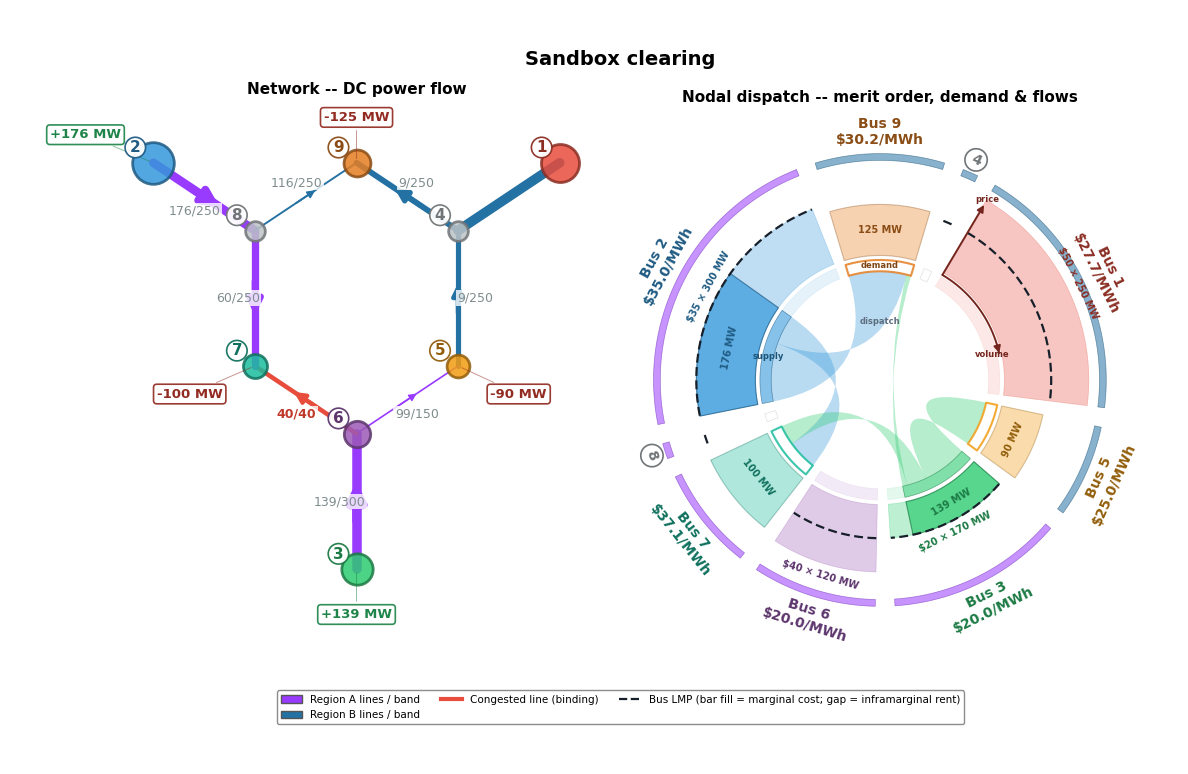

Sandbox -- settlement by node:

,LMP ($/MWh),gen (MW),paid to gen ($/h),load (MW),paid by load ($/h)
bus,,,,,
1,27.74,0.0,0.0,0.0,0.0
2,35.0,176.1,6162.4,0.0,0.0
3,20.0,138.9,2778.6,0.0,0.0
4,27.74,0.0,0.0,0.0,0.0
5,25.02,0.0,0.0,90.0,2251.8
6,20.0,0.0,0.0,0.0,0.0
7,37.13,0.0,0.0,100.0,3712.6
8,35.0,0.0,0.0,0.0,0.0
9,30.25,0.0,0.0,125.0,3780.8


Sandbox -- marginal value of line capacity (shadow price x flow, TOTAL = congestion rent):

,from,to,flow (MW),rating (MW),binding,|mu| ($/MWh = value of +1 MW),rent |mu| x flow ($/h)
line,,,,,,,
line_0,1,4,-0.0,250.0,False,0.0,0.0
line_1,4,5,-8.9,250.0,False,0.0,0.0
line_2,5,6,-98.9,150.0,False,0.0,0.0
line_3,3,6,138.9,300.0,False,0.0,0.0
line_4,6,7,40.0,40.0,True,20.1,804.1
line_5,7,8,-60.0,250.0,False,0.0,0.0
line_6,8,2,-176.1,250.0,False,0.0,0.0
line_7,8,9,116.1,250.0,False,0.0,0.0
line_8,9,4,-8.9,250.0,False,0.0,0.0


per-region congestion N_a^c sums to R only when no self-schedule trader is present (a self-schedule carries its own congestion leg -- see the position ledger).

,Region A,Region B,TOTAL
Load payment L_a,3712.6,6032.5,9745.1
Gen revenue WITHIN region G_a,8941.0,0.0,8941.0
Net import e_a (MW),-215.0,215.0,-0.0
Imported energy @ lambda (lambda*e_a),-6358.5,5963.3,-395.2
Generation payment serving region (G_a + lambda*e_a),2582.5,5963.3,8545.8
Congestion revenue by region N_a^c,1130.1,69.2,1199.3


INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


autarky/Pareto ledger (congestion rent rebated pro-rata by load):

Region A           Region B              TOTAL
                                       Consumer Generator Consumer Generator         
Autarky: payment / revenue              -3712.6    2908.5 -10750.0   10750.0   -804.1
Autarky: production cost                          -2908.5           -10750.0 -13658.5
Autarky: own congestion rent (CRR)        804.1                0.0              804.1
Autarky: position                       -2908.5       0.0 -10750.0       0.0 -13658.5
Unified: payment / revenue              -3712.6    8941.0  -6032.5       0.0   -804.1
Unified: production cost                          -8941.0               -0.0  -8941.0
Unified: congestion rent -- system (R)                                          804.1
Unified: congestion by region (N_a^c)    1130.1               69.2             1199.3
Unified: transfer settlement (T_E)                                             -395.2
Unified: Congestion Revenue Allocation    255.3              548.8              804.1
Final position                          -3457.3       0.0  -5483.7       0.0  -8941.0
Delta vs autarky                         -548.8       0.0   5266.3       0.0   4717.5
Pareto (Delta >= 0)                          no       yes      yes       yes

In [10]:
# -- EDIT -- a full free-form scenario. Every main input is configurable, and a
# bus may gain or lose a generator/load it did not start with.
# Generators -- {bus: (marginal cost $/MWh, capacity MW)}. Add a unit at a
# load-only bus (uncomment bus 5), drop one, or re-cost / re-size any.
SB_GENS = {
    "1": (50.0, 250.0),    # slack, most expensive
    "2": (35.0, 300.0),    # mid-merit
    "3": (20.0, 170.0),    # cheapest
    "6": (40.0, 120.0),  # <- e.g. put a generator where there was only load
}
SB_LOADS = {"5": 90.0, "7": 100.0, "9": 125.0}   # {bus: MW}; add/resize load at any bus
SB_RATINGS  = {"line_4": 40.0}   # line limits (congestion); {} = none
SB_TRANSFER = None               # MW released capacity on the region interface (None = off)
SB_SELF     = {}                 # {bus: MW} self-schedule (price-taking); {} = none
SHED_PRICE  = 150.0              # load-shed penalty ($/MWh)
# ---------------------------------------------------------------------------
SB_FLEET = {f"gen_{b}": {"bus": b, "cost": c, "p_nom": p} for b, (c, p) in SB_GENS.items()}
n_sb = build_network(SB_RATINGS); p_sb = compute_ptdf(n_sb, slack_bus="1")
eng_sb = make_engine("UNIFIED", buses=p_sb.buses, gen_fleet=SB_FLEET, loads=SB_LOADS)
if SB_TRANSFER is not None:                      # released capacity on the declared interface
    r_sb = solve_engine_transfers(p_sb, eng_sb, fp.defs, {tuple(sorted(fp.names)): float(SB_TRANSFER)},
                                  exo=(SB_SELF or None), shed_price=SHED_PRICE)
else:
    r_sb = solve_engine_dispatch(p_sb, eng_sb, exo=(SB_SELF or None), shed_price=SHED_PRICE)

R  = ra.allocate_congestion_rent(fp, r_sb, p_sb, SB_LOADS)[1]["R"]
RT = ra.transfer_rent(r_sb)
print(f"congestion rent  R = ${R:,.1f}/h    transfer rent  R_T = ${RT:,.1f}/h    "
      f"load shed: {sum(r_sb.shed_by_bus.values()):.0f} MW")

# Colors follow the sandbox fleet so a newly-active bus gets its own color.
_sbsup = {}
for _g, _s in SB_FLEET.items():
    _sbsup.setdefault(_s["bus"], []).append(_s)
sb_colors = assign_bus_colors(p_sb.buses, _sbsup, SB_LOADS)

figs.footprint_figure(n_sb, p_sb, fp, eng_sb, r_sb, exo_sched=(SB_SELF or None),
                      bus_colors=sb_colors, node_net_mw=True, suptitle="Sandbox clearing")
plt.show()
# Two settlement ledgers for the sandbox clearing -- the SAME pair as Section 2: settlement
# by node (paid by load vs paid to gen; the 'Total - congestion rent' row is the gap) and the
# marginal value of line capacity (|shadow price| x flow, TOTAL = the same congestion rent).
from revenue_allocation import settlement_by_bus, capacity_value_by_line
sb_node = settlement_by_bus(r_sb, p_sb.buses, SB_LOADS)
_lp = sb_node.loc['SUBTOTAL', 'paid by load ($/h)']; _gp = sb_node.loc['SUBTOTAL', 'paid to gen ($/h)']
sb_node.loc['Total - congestion rent'] = ['', '', '', '', round(_lp - _gp, 1)]
print('Sandbox -- settlement by node:')
display(sb_node)
print('Sandbox -- marginal value of line capacity (shadow price x flow, TOTAL = congestion rent):')
display(capacity_value_by_line(r_sb, p_sb, p_sb.lines))

# Per-region decomposition (eqs 5-10):  L_a = G_a + lambda*e_a + N_a^c  (the scheduled
# transfer settles system-wide as T_E, not per region).
rc_sb = ra.regional_congestion(fp, r_sb, p_sb, SB_LOADS)
sb_tbl = pd.DataFrame({reg: {
    'Load payment  L_a':                                     rc_sb[reg]['load_pay'],
    'Gen revenue WITHIN region  G_a':                        rc_sb[reg]['gen_rev_within'],
    'Net import  e_a  (MW)':                                 rc_sb[reg]['net_import'],
    'Imported energy @ lambda  (lambda*e_a)':                rc_sb[reg]['energy_payment'],
    'Generation payment serving region  (G_a + lambda*e_a)': rc_sb[reg]['gen_payment'],
    'Congestion revenue by region  N_a^c':                   rc_sb[reg]['line_congestion'],
} for reg in fp.areas})
sb_tbl['TOTAL'] = sb_tbl.sum(axis=1)
print('per-region congestion N_a^c sums to R only when no self-schedule trader is present '
      '(a self-schedule carries its own congestion leg -- see the position ledger).')
display(sb_tbl.round(1))

# Autarky/Pareto ledger for the sandbox clearing -- the same chain as Sections 3 and 4: the system
# rent R splits into the congestion each region creates (N_a^c), a pro-rata-by-load uplift
# allocates it, and each region's consumers and generators are tested against autarky.
sb_cost = {s['bus']: s['cost'] for s in SB_FLEET.values()}
_, sb_indep = ra.independent_clear(fp, SB_RATINGS, gen_fleet=SB_FLEET, loads=SB_LOADS, shed_price=SHED_PRICE)
_Rsb = sum(ra.ba_settlement(fp, r_sb, SB_LOADS)[reg]['net_into_pool'] for reg in fp.names)
_loadsb = {reg: sum(SB_LOADS.get(b, 0.0) for b in fp.defs[reg]) for reg in fp.names}
sb_prorata = pd.DataFrame({'method1': {reg: _Rsb * _loadsb[reg] / (sum(_loadsb.values()) or 1.0)
                                       for reg in fp.names}})
print()
print('autarky/Pareto ledger (congestion rent rebated pro-rata by load):')
display(ra.autarky_vs_unified_congestion(fp, 1, sb_prorata, sb_indep, r_sb, p_sb,
                                         loads=SB_LOADS, cost=sb_cost))